# Встреча 4. Остановка: практика

> **Время:** 55 минут · **Опирается на:** `theory.ipynb` · **Данные:** `../data/hotdeals_segmented.csv` · **Артефакт:** `stopping_policy.md`

**Легенда.** Сервис бронирования отелей добавил на главную блок **«Горящие предложения»**: скидочные варианты должны подтолкнуть к бронированию. В тест приходит около **6 000 новых пользователей в день**, сплит 50/50, по 3 000 человек в группе. Единица рандомизации и анализа — пользователь, момент попадания в тест — первый заход на главную.

Продакт хочет смотреть результат **каждый день** и остановить тест, как только «стало значимо». От вас — план, который это разрешает и не ломает ошибку, и политика остановки для команды.

| Метрика | Роль | Что хотим |
| --- | --- | --- |
| Конверсия в бронирование | основная | рост, MDE +0.5 п.п. при базе 4.8% |
| Выручка на пользователя | основная | рост |
| Доля пользователей с отменой брони | контрольная (guardrail) | не вырасти |

**Правило решения.** Раскатываем, если значимо выросла хотя бы одна основная метрика, а контрольная значимо не ухудшилась. Основных метрик две, поэтому по Бонферрони каждая получает $\alpha = 2.5\%$. Контрольная в поправке не участвует: она не открывает раскатку, а только запрещает её.

| № | Задание | Минут |
| :---: | --- | :---: |
| 1 | Цена подглядывания на нашем расписании | 8 |
| 2 | План GST: границы O'Brien-Fleming и Pocock, запас выборки | 14 |
| 3 | mSPRT и выбор $\tau$ из плана | 8 |
| 4 | Futility: условная мощность, binding и non-binding | 10 |
| 5 | Прогон лога: завышение эффекта и честный отчёт | 10 |
| 6 | Решение и политика остановки | 5 |

Формат: задание → ячейка `# ВАШ КОД` → свёрнутое решение → ячейка «Проверка» с `assert`.

* **Свой код проверяйте так:** запустите свою ячейку, затем сразу «Проверку», пропустив ячейку решения.
* **Решение перезаписывает ваши переменные и функции.** Поэтому не нажимайте Run All, если проверяете своё: он выполнит решения поверх вашего кода. На незаполненной заглушке Run All остановится с `NotImplementedError`.
* **Застряли больше 5 минут** — запустите решение: дальше ноутбук опирается на его переменные.
* Симуляции в ячейках занимают до 10–20 секунд: это нормально.

## 0. Подготовка

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from scipy.optimize import brentq

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

BLUE, RED, GREEN, GRAY, ORANGE = "#4C72B0", "#C44E52", "#55A868", "#7F7F7F", "#DD8452"
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
norm = stats.norm

### План теста

Параметры, зафиксированные до запуска. Базовая конверсия — по истории сервиса.

In [2]:
ALPHA = 0.05                 # общий уровень на решение
ALPHA_PRIMARY = ALPHA / 2    # на каждую из двух основных метрик (Бонферрони), двусторонний
POWER = 0.80
P_BASE = 0.048               # конверсия по истории
MDE = 0.005                  # +0.5 п.п.
N_DAY = 3_000                # пользователей в группе за день
PLAN_DAYS = 14               # две полные недели
DATA = Path("../data/hotdeals_segmented.csv")

### Данные

Из-за заморозки релизов блок проработал не две недели, а **четыре**, поэтому в логе 28 дней. Сначала играем тест так, как он шёл бы в реальности: день за днём и только на **первых 14 днях** (`plan_logs`). Дни 15–28 откроем в задании 6.

Одна строка — один пользователь. Нам нужны `date`, `group`, `booked`, `revenue`, `cancelled`; остальные колонки (устройство, новизна, активность) понадобятся на встрече 6. Готовая функция `daily_cumulative(df, metric)` возвращает накопленные по дням `n_a`, `n_b`, `diff` $= \bar x_B - \bar x_A$ и `V` $= \hat\sigma_A^2/n_A + \hat\sigma_B^2/n_B$.

In [3]:
logs = pd.read_csv(DATA, parse_dates=["date"])
logs["day"] = (logs["date"] - logs["date"].min()).dt.days + 1
print(logs.shape, f"период: {logs['date'].min():%Y-%m-%d} ({logs['date'].min():%A}) — {logs['date'].max():%Y-%m-%d}")

plan_logs = logs[logs["day"] <= PLAN_DAYS]
counts = plan_logs["group"].value_counts().reindex(["A", "B"])
print(f"Дни 1–14: A {counts['A']:,}, B {counts['B']:,}, SRM p-value = {stats.chisquare(counts).pvalue:.3f}")
print(f"Пользователей в группе за день: {plan_logs.groupby(['day', 'group']).size().mean():,.0f}; "
      f"конверсия A: {plan_logs.loc[plan_logs['group'] == 'A', 'booked'].mean():.2%}")


def daily_cumulative(df: pd.DataFrame, metric: str) -> pd.DataFrame:
    """Накопленные по дням размеры групп, разность средних и её дисперсия."""
    grouped = (df.assign(square=df[metric] ** 2).groupby(["day", "group"])
               .agg(n=(metric, "size"), total=(metric, "sum"), squares=("square", "sum")).unstack().cumsum())
    n_a, n_b = grouped[("n", "A")], grouped[("n", "B")]
    mean_a, mean_b = grouped[("total", "A")] / n_a, grouped[("total", "B")] / n_b
    var_a = grouped[("squares", "A")] / n_a - mean_a ** 2
    var_b = grouped[("squares", "B")] / n_b - mean_b ** 2
    return pd.DataFrame({"n_a": n_a, "n_b": n_b, "mean_a": mean_a, "mean_b": mean_b,
                         "diff": mean_b - mean_a, "V": var_a / n_a + var_b / n_b})


cum_conv = daily_cumulative(plan_logs, "booked")
plan_logs.head(3)

(168158, 13) период: 2026-09-07 (Monday) — 2026-10-04
Дни 1–14: A 41,958, B 42,027, SRM p-value = 0.812


Пользователей в группе за день: 2,999; конверсия A: 4.75%


,user_id,date,group,booked,revenue,cancelled,device,reg_date,tenure_days,is_new,orders_90d,segment,day
0,100000,2026-09-07,B,0,0,0,mobile,2026-03-08,183,0,2,mid,1
1,100001,2026-09-07,A,0,0,0,mobile,2026-08-27,11,1,1,low,1
2,100002,2026-09-07,B,0,0,0,web,2026-05-30,100,0,4,mid,1


Сплит держится (SRM нет), трафик — около 3 000 на группу в день, в выходные больше. Тест стартовал в понедельник.

## Задание 1. Цена подглядывания (8 минут)

Реализуйте `peeking_fpr(look_days, ...)`: для `R` A/A-тестов сгенерируйте дневные числа конверсий из биномиального распределения (`n_day` пользователей в группе, конверсия `p`), посчитайте накопленные итоги и на днях из `look_days` примените обычный z-тест с объединённой долей. Функция возвращает долю тестов, значимых **хотя бы на одном** взгляде.

In [4]:
def peeking_fpr(look_days, p: float = P_BASE, n_day: int = N_DAY, R: int = 100_000,
                alpha: float = ALPHA, seed: int = 1) -> float:
    # ВАШ КОД
    raise NotImplementedError

In [5]:
# @title Решение (нажмите, чтобы раскрыть)
def peeking_fpr(look_days, p: float = P_BASE, n_day: int = N_DAY, R: int = 100_000,
                alpha: float = ALPHA, seed: int = 1) -> float:
    rng = np.random.default_rng(seed)
    look_days = np.asarray(look_days)
    days = look_days.max()
    x_a = rng.binomial(n_day, p, (R, days)).cumsum(axis=1)[:, look_days - 1]
    x_b = rng.binomial(n_day, p, (R, days)).cumsum(axis=1)[:, look_days - 1]
    n = n_day * look_days
    pool = (x_a + x_b) / (2 * n)
    z = (x_b - x_a) / n / np.sqrt(2 * pool * (1 - pool) / n)
    return float((np.abs(z) > norm.ppf(1 - alpha / 2)).any(axis=1).mean())

In [6]:
# Проверка
one_look = peeking_fpr([PLAN_DAYS])
daily = peeking_fpr(np.arange(1, PLAN_DAYS + 1))
assert 0.045 < one_look < 0.055, "Один взгляд должен давать около 5%"
assert 0.18 < daily < 0.27, "14 взглядов должны заметно завышать ошибку"
print(f"Один взгляд: {one_look:.3f}, каждый день: {daily:.3f}")
print("Задание 1 принято")

Один взгляд: 0.050, каждый день: 0.218
Задание 1 принято


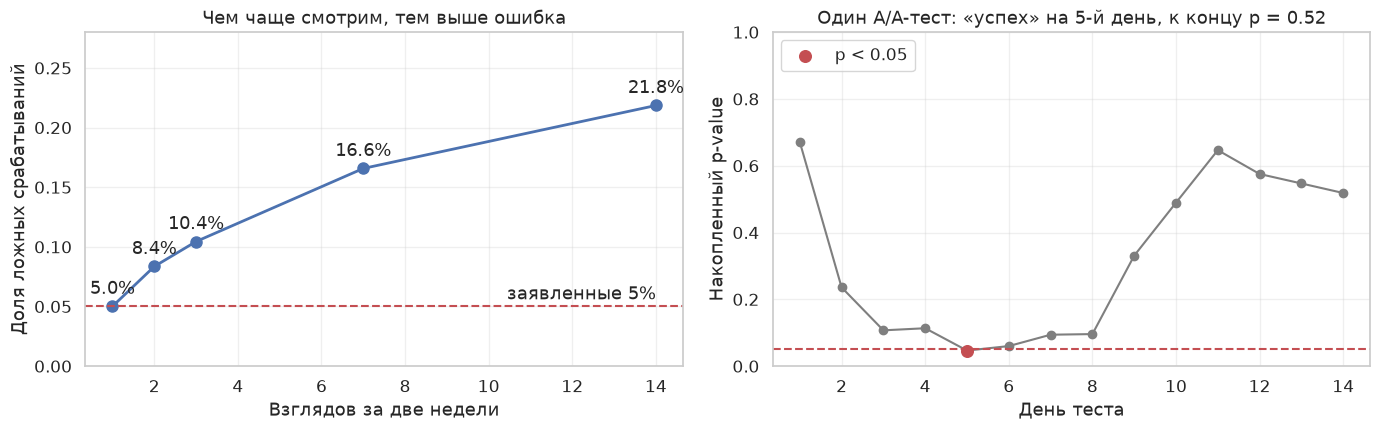

,1,2,3,7,14
Ложных срабатываний,0.050,0.084,0.104,0.166,0.218


In [7]:
schedules = {1: [14], 2: [7, 14], 3: [5, 10, 14], 7: [2, 4, 6, 8, 10, 12, 14], 14: list(range(1, 15))}
fpr_by_looks = pd.Series({k: peeking_fpr(days) for k, days in schedules.items()}, name="Ложных срабатываний")


def aa_pvalues(seed: int) -> np.ndarray:
    """Накопленный p-value одного A/A-теста по дням."""
    rng = np.random.default_rng(seed)
    x_a, x_b = (rng.binomial(N_DAY, P_BASE, PLAN_DAYS).cumsum() for _ in range(2))
    n = N_DAY * np.arange(1, PLAN_DAYS + 1)
    pool = (x_a + x_b) / (2 * n)
    z = (x_b - x_a) / n / np.sqrt(2 * pool * (1 - pool) / n)
    return 2 * norm.sf(np.abs(z))


example = next(s for s in range(1000) if (aa_pvalues(s) < ALPHA).any() and aa_pvalues(s)[-1] > 0.5)
path = aa_pvalues(example)
first_hit = int(np.argmax(path < ALPHA)) + 1

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(fpr_by_looks.index, fpr_by_looks.values, "-o", color=BLUE, linewidth=2, markersize=8)
axes[0].axhline(ALPHA, color=RED, linestyle="--", linewidth=1.5)
axes[0].text(14, ALPHA + 0.006, "заявленные 5%", ha="right")
for k, v in fpr_by_looks.items():
    axes[0].annotate(f"{v:.1%}", (k, v), textcoords="offset points", xytext=(0, 9), ha="center")
axes[0].set(xlabel="Взглядов за две недели", ylabel="Доля ложных срабатываний", ylim=(0, 0.28),
            title="Чем чаще смотрим, тем выше ошибка")
days = np.arange(1, PLAN_DAYS + 1)
axes[1].plot(days, path, "-o", color=GRAY, linewidth=1.5)
axes[1].scatter(days[path < ALPHA], path[path < ALPHA], color=RED, s=70, zorder=3, label="p < 0.05")
axes[1].axhline(ALPHA, color=RED, linestyle="--", linewidth=1.5)
axes[1].set(xlabel="День теста", ylabel="Накопленный p-value", ylim=(0, 1),
            title=f"Один A/A-тест: «успех» на {first_hit}-й день, к концу p = {path[-1]:.2f}")
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()
fpr_by_looks.to_frame().T

Ежедневный взгляд в обычный тест даёт около 22% ложных срабатываний вместо 5%: один ложный запуск на пять тестов без эффекта. Даже два взгляда дают 8%. Справа — типичный A/A-тест: «значимо» в первые дни, а к концу p-value больше 0.5.

**Вопрос.** Почему 14 взглядов — это не 14 независимых шансов и почему поправка Бонферрони $0.05/14$ здесь плохой выход?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Накопленные статистики соседних дней сильно зависимы: $\operatorname{corr}(Z_s, Z_t) = \sqrt{s/t}$. При 14 независимых проверках ошибка была бы $1 - 0.95^{14} \approx 51\%$, а реально около 22%. Бонферрони считает проверки независимыми и поэтому слишком строг: держит ошибку ниже 5% ценой лишней потери мощности. Границы GST учитывают зависимость точно.

</details>

## Задание 2. План GST: границы и запас выборки (14 минут)

**Функции расхода** уже готовы. $\alpha(t)$ — **накопленная** ошибка к доле данных $t$. Граница $b_i$ для $|Z|$ подбирается так, чтобы на взгляде $i$ потратить ровно прирост $\alpha(t_i) - \alpha(t_{i-1})$. Генератор `null_paths` даёт пути z-статистики при верной $H_0$, `drift_paths` — при эффекте: в единицах $Z$ при $N_{\max}$ снос равен $\theta$, а путь — $Z(t) = (W(t) + \theta t)/\sqrt{t}$.

In [8]:
def obf_spending(t, alpha):
    """O'Brien-Fleming в форме Lan-DeMets."""
    return 2 * norm.sf(norm.ppf(1 - alpha / 2) / np.sqrt(t))


def pocock_spending(t, alpha):
    """Pocock в форме Lan-DeMets."""
    return alpha * np.log(1 + (np.e - 1) * t)


def drift_paths(looks, drift: float, n_paths: int, seed: int) -> np.ndarray:
    """Пути z-статистики в долях данных looks при сносе drift (в единицах Z при t = 1)."""
    looks = np.asarray(looks, dtype=float)
    rng = np.random.default_rng(seed)
    gaps = np.diff(looks, prepend=0.0)
    walk = rng.standard_normal((n_paths, len(looks)), dtype=np.float32) * np.sqrt(gaps) + drift * gaps
    return np.cumsum(walk, axis=1) / np.sqrt(looks)


def null_paths(looks, n_paths: int, seed: int = 11) -> np.ndarray:
    """Пути z-статистики при верной H0."""
    return drift_paths(looks, 0.0, n_paths, seed)

**2а. Границы.** Реализуйте `gst_boundaries(spending, looks, alpha, n_paths, seed)`:

1. сгенерируйте `n_paths` нулевых путей (`null_paths`) и возьмите $|Z|$;
2. на взгляде $i$ среди ещё не остановившихся путей подберите границу так, чтобы за неё вышла доля $\alpha(t_i) - \alpha(t_{i-1})$ от **всех** путей (подсказка: `np.partition`);
3. если на эту долю приходится меньше 100 путей, симуляция ненадёжна — берите границу аналитически: `norm.isf(step / 2)`.

**2б. Мощность.** Реализуйте `gst_power(boundaries, looks, drift, ...)` → (мощность, средняя доля потраченной выборки). Путь останавливается на первом $|Z| \ge b_i$; если граница не пройдена, тест доходит до конца ($t = 1$).

Готовая `inflation_factor` подбирает запас $R = N_{\max} / n_{\text{fixed}}$, при котором мощность при MDE равна 80%: при $N_{\max} = R \cdot n_{\text{fixed}}$ снос равен $(z_{1-\alpha/2} + z_{1-\beta})\sqrt{R}$.

In [9]:
def gst_boundaries(spending, looks, alpha: float = ALPHA_PRIMARY,
                   n_paths: int = 1_000_000, seed: int = 11) -> np.ndarray:
    # ВАШ КОД
    raise NotImplementedError

In [10]:
def gst_power(boundaries, looks, drift: float, n_paths: int = 200_000, seed: int = 5) -> tuple:
    # ВАШ КОД
    raise NotImplementedError

In [11]:
# @title Решение (нажмите, чтобы раскрыть)
def gst_boundaries(spending, looks, alpha: float = ALPHA_PRIMARY,
                   n_paths: int = 1_000_000, seed: int = 11) -> np.ndarray:
    looks = np.asarray(looks, dtype=float)
    z = np.abs(null_paths(looks, n_paths, seed))
    alive = np.ones(n_paths, dtype=bool)
    spent, bounds = 0.0, []
    for i, t in enumerate(looks):
        step = float(spending(t, alpha)) - spent
        spent += step
        values = z[alive, i]
        k = int(step * n_paths)
        bound = np.partition(values, -k)[-k] if k >= 100 else norm.isf(step / 2)
        bounds.append(bound)
        alive[alive] = values < bound
    return np.array(bounds)


def gst_power(boundaries, looks, drift: float, n_paths: int = 200_000, seed: int = 5) -> tuple:
    looks = np.asarray(looks, dtype=float)
    z = drift_paths(looks, drift, n_paths, seed)
    hits = np.abs(z) >= boundaries
    fired = hits.any(axis=1)
    first = np.where(fired, hits.argmax(axis=1), len(looks) - 1)
    return float(fired.mean()), float(looks[first].mean())

In [12]:
# Проверка
def inflation_factor(boundaries, looks, alpha: float = ALPHA_PRIMARY, power: float = POWER) -> float:
    """Запас R, при котором мощность GST при MDE равна заданной."""
    z_sum = norm.ppf(1 - alpha / 2) + norm.ppf(power)
    return brentq(lambda r: gst_power(boundaries, looks, z_sum * np.sqrt(r))[0] - power, 1.0, 1.6, xtol=1e-3)


# табличные границы O'Brien-Fleming при 5 равных взглядах и трате alpha / 2 на каждую сторону
reference = np.array([4.877, 3.357, 2.680, 2.290, 2.031])
per_side = lambda t, a: 2 * obf_spending(t, a / 2)
ours = gst_boundaries(per_side, np.arange(1, 6) / 5, alpha=0.05)
assert np.allclose(ours, reference, atol=0.03), f"Границы не совпали с таблицей: {ours.round(3)}"

LOOKS = np.arange(1, PLAN_DAYS + 1) / PLAN_DAYS
BOUNDS_OBF = gst_boundaries(obf_spending, LOOKS)
BOUNDS_POCOCK = gst_boundaries(pocock_spending, LOOKS)
fresh = np.abs(null_paths(LOOKS, 1_000_000, seed=99))
fpr_obf, fpr_pocock = ((fresh >= b).any(axis=1).mean() for b in (BOUNDS_OBF, BOUNDS_POCOCK))
assert abs(fpr_obf - ALPHA_PRIMARY) < 0.002 and abs(fpr_pocock - ALPHA_PRIMARY) < 0.002, "Ошибка на новых путях ≠ 2.5%"

assert abs(gst_power(np.array([norm.ppf(1 - ALPHA_PRIMARY / 2)]), np.array([1.0]), 2.8)[0] - norm.sf(norm.ppf(1 - ALPHA_PRIMARY / 2) - 2.8)) < 0.005
R_OBF = inflation_factor(BOUNDS_OBF, LOOKS)
R_POCOCK = inflation_factor(BOUNDS_POCOCK, LOOKS)
assert 1.0 < R_OBF < R_POCOCK < 1.4
print(f"Ложных срабатываний на новых путях: O'Brien-Fleming {fpr_obf:.4f}, Pocock {fpr_pocock:.4f} при цели {ALPHA_PRIMARY}")
print(f"Запас выборки: O'Brien-Fleming {R_OBF:.3f}, Pocock {R_POCOCK:.3f}")
print("Задание 2 принято")

Ложных срабатываний на новых путях: O'Brien-Fleming 0.0246, Pocock 0.0245 при цели 0.025
Запас выборки: O'Brien-Fleming 1.048, Pocock 1.244
Задание 2 принято


Соберём план: сколько нужно пользователей при каждом методе и сколько в среднем потратим.

Фиксированный тест: 36,456 на группу, 12.2 дня


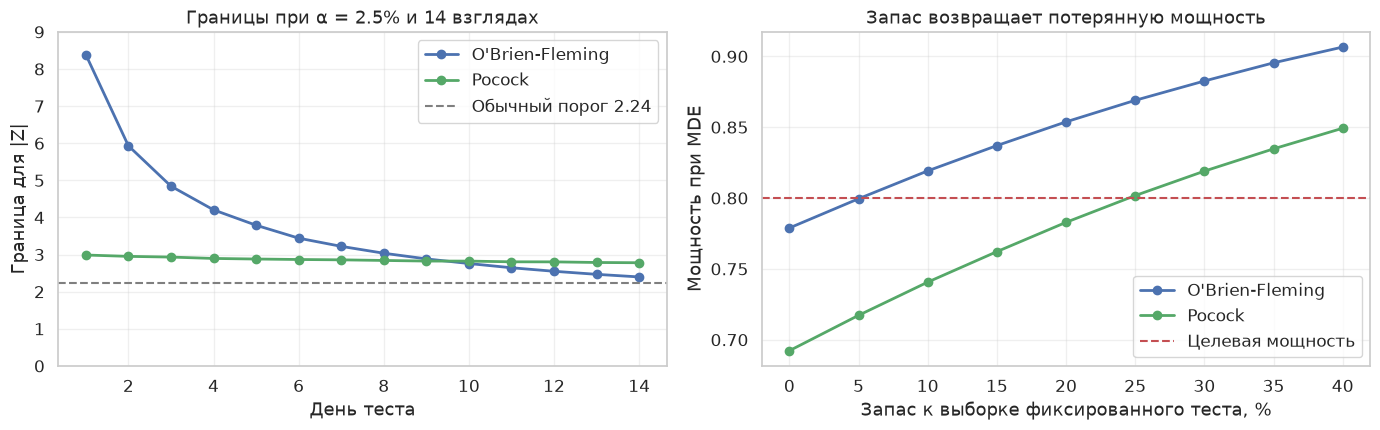

,Запас R,Nmax на группу,Дней до Nmax,"E[n] при H0, % от fixed","E[n] при MDE, % от fixed","E[n] при 1.5 MDE, % от fixed"
Фиксированный тест,1.000,"36,456.000",12.152,100.000,100.000,100.000
"GST, O'Brien-Fleming",1.048,"38,209.000",12.736,104.319,79.132,56.121
"GST, Pocock",1.244,"45,365.000",15.122,122.799,78.948,45.072


In [13]:
def fixed_n(mde: float, p: float = P_BASE, alpha: float = ALPHA_PRIMARY, power: float = POWER) -> float:
    """Размер группы фиксированного теста для конверсии."""
    z_sum = norm.ppf(1 - alpha / 2) + norm.ppf(power)
    return z_sum ** 2 * (p * (1 - p) + (p + mde) * (1 - p - mde)) / mde ** 2


n_fixed = fixed_n(MDE)
z_sum = norm.ppf(1 - ALPHA_PRIMARY / 2) + norm.ppf(POWER)
rows = {}
for name, bounds, r in [("Фиксированный тест", np.array([norm.ppf(1 - ALPHA_PRIMARY / 2)]), 1.0),
                        ("GST, O'Brien-Fleming", BOUNDS_OBF, R_OBF),
                        ("GST, Pocock", BOUNDS_POCOCK, R_POCOCK)]:
    grid = LOOKS if len(bounds) > 1 else np.array([1.0])
    shares = [gst_power(bounds, grid, z_sum * np.sqrt(r) * eff)[1] for eff in (0.0, 1.0, 1.5)]
    rows[name] = {"Запас R": r, "Nmax на группу": round(n_fixed * r), "Дней до Nmax": n_fixed * r / N_DAY,
                  "E[n] при H0, % от fixed": 100 * r * shares[0], "E[n] при MDE, % от fixed": 100 * r * shares[1],
                  "E[n] при 1.5 MDE, % от fixed": 100 * r * shares[2]}
plan = pd.DataFrame(rows).T
print(f"Фиксированный тест: {n_fixed:,.0f} на группу, {n_fixed / N_DAY:.1f} дня")

grid_r = np.linspace(1.0, 1.4, 9)
power_obf = [gst_power(BOUNDS_OBF, LOOKS, z_sum * np.sqrt(r), n_paths=100_000)[0] for r in grid_r]
power_pocock = [gst_power(BOUNDS_POCOCK, LOOKS, z_sum * np.sqrt(r), n_paths=100_000)[0] for r in grid_r]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(days, BOUNDS_OBF, "-o", color=BLUE, linewidth=2, label="O'Brien-Fleming")
axes[0].plot(days, BOUNDS_POCOCK, "-o", color=GREEN, linewidth=2, label="Pocock")
axes[0].axhline(norm.ppf(1 - ALPHA_PRIMARY / 2), color=GRAY, linestyle="--", linewidth=1.5,
                label=f"Обычный порог {norm.ppf(1 - ALPHA_PRIMARY / 2):.2f}")
axes[0].set(xlabel="День теста", ylabel="Граница для |Z|", ylim=(0, 9), title="Границы при α = 2.5% и 14 взглядах")
axes[0].legend()
axes[1].plot(100 * (grid_r - 1), power_obf, "-o", color=BLUE, linewidth=2, label="O'Brien-Fleming")
axes[1].plot(100 * (grid_r - 1), power_pocock, "-o", color=GREEN, linewidth=2, label="Pocock")
axes[1].axhline(POWER, color=RED, linestyle="--", linewidth=1.5, label="Целевая мощность")
axes[1].set(xlabel="Запас к выборке фиксированного теста, %", ylabel="Мощность при MDE",
            title="Запас возвращает потерянную мощность")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()
plan

Что показывает таблица:

* **O'Brien-Fleming** просит запас около 5% и при эффекте, равном MDE, тратит в среднем ~80% выборки фиксированного теста. Ранние границы очень высокие (8.4 в первый день): остановиться рано можно только при огромном эффекте.
* **Pocock** просит запас около 25%. Выигрыш по средней выборке он даёт только при сильном эффекте (1.5 MDE).
* Плата за страховку есть всегда: если эффекта нет, O'Brien-Fleming тратит ~104% фиксированной выборки, Pocock — ~123%.

Выбираем **O'Brien-Fleming**. Выборку округляем вверх до целых недель: 12.7 дня превращаются в 14, $N_{\max} = 42\,000$ на группу. Pocock потребовал бы 15.2 дня — уже три недели.

**Вопрос.** Продакт спрашивает: «Pocock же разрешает остановиться раньше — почему не он?»

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Pocock тратит $\alpha$ равномерно, поэтому ранние границы ниже, но последняя выше обычной (~2.8 против 2.24 у фиксированного теста). Цена — +25% к максимальной выборке и лишняя неделя календаря. Выигрыш есть только при эффекте заметно больше MDE, а на таких эффектах O'Brien-Fleming тоже останавливается рано. Ранняя остановка при Pocock к тому же сильнее завышает оценку (задание 5): чем ниже ранняя граница, тем чаще её проходит шум.

</details>

In [14]:
N_MAX = PLAN_DAYS * N_DAY
SIGMA2_DIFF = P_BASE * (1 - P_BASE) + (P_BASE + MDE) * (1 - P_BASE - MDE)
V_PLAN = SIGMA2_DIFF / N_MAX
THETA_MDE = MDE / np.sqrt(V_PLAN)         # снос при эффекте MDE в единицах Z на Nmax
power_plan = gst_power(BOUNDS_OBF, LOOKS, THETA_MDE)[0]
print(f"Nmax = {N_MAX:,} на группу, две полные недели. Снос при MDE θ = {THETA_MDE:.2f}, "
      f"мощность O'Brien-Fleming: {power_plan:.3f}")

Nmax = 42,000 на группу, две полные недели. Снос при MDE θ = 3.31, мощность O'Brien-Fleming: 0.839


## Задание 3. mSPRT и выбор $\tau$ (8 минут)

GST требует заранее зафиксировать $N_{\max}$. mSPRT этого не требует, но просит параметр смеси $\tau$. Через $V = \widehat{\mathrm{Var}}(\bar\Delta)$:

$$
\log\Lambda = \frac{1}{2}\log\frac{V}{V + \tau^2} + \frac{\bar\Delta^2 \tau^2}{2V(V + \tau^2)}, \qquad
r = \sqrt{\frac{2V(V + \tau^2)}{\tau^2}\left(\log\frac{1}{\alpha} + \frac{1}{2}\log\frac{V + \tau^2}{V}\right)}
$$

$r$ — полуширина доверительной последовательности: $\bar\Delta \pm r$ накрывает эффект одновременно на всех днях. **Откуда взять $\tau$:** так, чтобы ширина была минимальна там, где мы рассчитываем принимать решение, при плановом $V_{\text{план}}$:

$$
\tau^2 \approx c \cdot V_{\text{план}}, \qquad c = -2\log\alpha + \log(1 - 2\log\alpha)
$$

Реализуйте `msprt_log_lambda`, `msprt_radius`, `always_valid_p` и `tau_from_plan`. Always-valid p-value — накопленный минимум: $p_n = \min(p_{n-1}, 1/\Lambda_n)$, $p_0 = 1$.

In [15]:
def msprt_log_lambda(diff, V, tau: float):
    # ВАШ КОД
    raise NotImplementedError


def msprt_radius(V, tau: float, alpha: float = ALPHA_PRIMARY):
    # ВАШ КОД
    raise NotImplementedError


def always_valid_p(diff, V, tau: float) -> np.ndarray:
    # ВАШ КОД
    raise NotImplementedError


def tau_from_plan(V_plan: float, alpha: float = ALPHA_PRIMARY) -> float:
    # ВАШ КОД
    raise NotImplementedError

In [16]:
# @title Решение (нажмите, чтобы раскрыть)
def msprt_log_lambda(diff, V, tau: float):
    return 0.5 * np.log(V / (V + tau ** 2)) + diff ** 2 * tau ** 2 / (2 * V * (V + tau ** 2))


def msprt_radius(V, tau: float, alpha: float = ALPHA_PRIMARY):
    return np.sqrt(2 * V * (V + tau ** 2) / tau ** 2 * (np.log(1 / alpha) + 0.5 * np.log((V + tau ** 2) / V)))


def always_valid_p(diff, V, tau: float) -> np.ndarray:
    return np.minimum.accumulate(np.minimum(1.0, np.exp(-msprt_log_lambda(diff, V, tau))))


def tau_from_plan(V_plan: float, alpha: float = ALPHA_PRIMARY) -> float:
    c = -2 * np.log(alpha) + np.log(1 - 2 * np.log(alpha))
    return float(np.sqrt(c * V_plan))

In [17]:
# Проверка
V_test, tau_test = 2.5e-6, 0.005
r_test = msprt_radius(V_test, tau_test)
assert np.isclose(msprt_log_lambda(r_test, V_test, tau_test), np.log(1 / ALPHA_PRIMARY)), "Интервал не обращает тест: на границе Λ = 1/α"
assert np.all(np.diff(always_valid_p(np.array([0.0, 0.01, 0.0]), np.full(3, V_test), tau_test)) <= 0), "p-value не должен расти"

TAU = tau_from_plan(V_PLAN)
tau_grid = np.geomspace(0.05, 20, 4000) * np.sqrt(V_PLAN)
tau_exact = tau_grid[np.argmin(msprt_radius(V_PLAN, tau_grid))]
assert abs(TAU / tau_exact - 1) < 0.05, "τ по формуле должен быть близок к численному минимуму ширины"
print(f"τ по формуле: {TAU:.5f}, численный минимум ширины: {tau_exact:.5f}")
print(f"τ / MDE при n = n_fixed: {tau_from_plan(SIGMA2_DIFF / n_fixed) / MDE:.3f}")
print("Задание 3 принято")

τ по формуле: 0.00466, численный минимум ширины: 0.00472
τ / MDE при n = n_fixed: 1.000
Задание 3 принято


**Вопрос.** Почему при $n = n_{\text{fixed}}$ получилось $\tau \approx$ MDE?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Подставим $V_{\text{план}} = \sigma_\Delta^2 / n_{\text{fixed}}$ и $n_{\text{fixed}} = (z_{1-\alpha/2} + z_{1-\beta})^2 \sigma_\Delta^2 / \delta^2$:

$$
\tau^2 \approx c \cdot \frac{\delta^2}{(z_{1-\alpha/2} + z_{1-\beta})^2}.
$$

При $\alpha = 2.5\%$ и мощности 80% $c = 9.50$ и $(z_{1-\alpha/2} + z_{1-\beta})^2 = 9.50$, поэтому $\tau \approx \delta$. Это совпадение обычных $\alpha$ и $\beta$, а не закон, но оно объясняет правило «$\tau$ близок к ожидаемому эффекту»: выбрать $\tau = $ MDE — значит настроить тест на выборку фиксированного теста. Мы настраиваем на $N_{\max}$, поэтому $\tau$ чуть меньше MDE.

</details>

Что стоит ошибка в $\tau$ и как mSPRT выглядит рядом с GST:

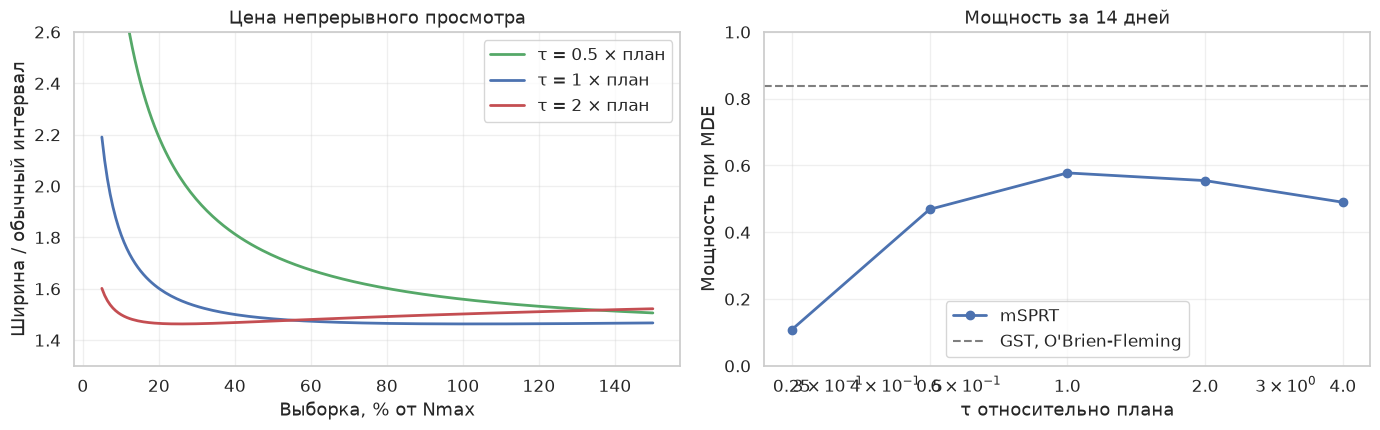

GST при MDE: мощность 0.839, средняя выборка 73.1% от Nmax; при 2 MDE — 38.8%


,Мощность при MDE,Доля выборки при MDE,Доля выборки при 2 MDE,Ложных срабатываний
τ / τ по плану,,,,
0.250,0.108,0.989,0.686,0.000
0.500,0.469,0.882,0.436,0.001
1.000,0.578,0.796,0.327,0.005
2.000,0.555,0.786,0.297,0.006
4.000,0.490,0.815,0.307,0.005


In [18]:
def msprt_operating(tau_unit: float, drift: float, n_paths: int = 100_000, seed: int = 5) -> tuple:
    """Мощность и средняя доля выборки mSPRT с ежедневными взглядами до Nmax (единицы: V = 1/t)."""
    z = drift_paths(LOOKS, drift, n_paths, seed)
    diff = z / np.sqrt(LOOKS)                      # оценка эффекта в единицах sqrt(V_plan)
    hits = msprt_log_lambda(diff, 1 / LOOKS, tau_unit) >= np.log(1 / ALPHA_PRIMARY)
    fired = hits.any(axis=1)
    return float(fired.mean()), float(LOOKS[np.where(fired, hits.argmax(axis=1), len(LOOKS) - 1)].mean())


tau_ratios = np.array([0.25, 0.5, 1, 2, 4])
rows = {}
for ratio in tau_ratios:
    unit = ratio * TAU / np.sqrt(V_PLAN)
    (power_1, share_1), (_, share_2), (fpr, _) = (msprt_operating(unit, d) for d in (THETA_MDE, 2 * THETA_MDE, 0.0))
    rows[ratio] = {"Мощность при MDE": power_1, "Доля выборки при MDE": share_1,
                   "Доля выборки при 2 MDE": share_2, "Ложных срабатываний": fpr}
operating = pd.DataFrame(rows).T
operating.index.name = "τ / τ по плану"
gst_power_mde, gst_share_mde = gst_power(BOUNDS_OBF, LOOKS, THETA_MDE)
gst_share_2 = gst_power(BOUNDS_OBF, LOOKS, 2 * THETA_MDE)[1]

share = np.linspace(0.05, 1.5, 200)
V_curve = V_PLAN / share
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ratio, color in [(0.5, GREEN), (1, BLUE), (2, RED)]:
    axes[0].plot(share * 100, msprt_radius(V_curve, ratio * TAU) / (norm.ppf(1 - ALPHA_PRIMARY / 2) * np.sqrt(V_curve)),
                 color=color, linewidth=2, label=f"τ = {ratio} × план")
axes[0].set(xlabel="Выборка, % от Nmax", ylabel="Ширина / обычный интервал", ylim=(1.3, 2.6), title="Цена непрерывного просмотра")
axes[0].legend()
axes[1].plot(tau_ratios, operating["Мощность при MDE"], "-o", color=BLUE, linewidth=2, label="mSPRT")
axes[1].axhline(gst_power_mde, color=GRAY, linestyle="--", linewidth=1.5, label="GST, O'Brien-Fleming")
axes[1].set(xscale="log", xticks=tau_ratios, xticklabels=tau_ratios, xlabel="τ относительно плана",
            ylabel="Мощность при MDE", ylim=(0, 1), title="Мощность за 14 дней")
axes[1].legend(loc="lower center")
plt.tight_layout()
plt.show()
print(f"GST при MDE: мощность {gst_power_mde:.3f}, средняя выборка {gst_share_mde:.1%} от Nmax; при 2 MDE — {gst_share_2:.1%}")
operating

* **Слева.** Интервал mSPRT шире обычного всегда; минимум ~1.46 обычной ширины — около планового объёма. Эту цену настройкой не убрать, можно только выбрать, где её минимизировать.
* **Справа.** Лучшая мощность при $\tau$ около плана, и она заметно ниже, чем у GST на той же выборке. Занижать $\tau$ вчетверо опасно, завышать — безопаснее.
* Ложных срабатываний около 0.5% при заявленных 2.5%: гарантия рассчитана на просмотр после каждого наблюдения, а мы смотрим раз в день. Отсюда и потеря мощности.

Плата за мощность покупает свободу: mSPRT можно продлевать и смотреть сколько угодно. Поэтому дальше используем **GST для решения о раскатке** (известен $N_{\max}$) и **mSPRT для guardrail** (вред ловим в любой день, горизонт не важен).

## Задание 4. Futility: остановка за бесперспективностью (10 минут)

GST останавливает тест, когда эффект доказан. Futility — когда доказать его **уже почти невозможно**: зачем жечь трафик ещё неделю? Мерило — **условная мощность** (conditional power, CP): вероятность к концу теста пройти финальную границу $b_K$ при текущем $z_t$ и предположении об эффекте $\theta$ (снос в единицах $Z$ при $N_{\max}$).

На шкале $B(t) = \sqrt{t} Z_t$ путь — броуновское движение со сносом $\theta$, и приращение $B(1) - B(t) \sim N(\theta(1-t),\ 1-t)$ не зависит от прошлого. Отсюда

$$
\mathrm{CP}(\theta) = 1 - \Phi\left(\frac{b_K - \sqrt{t}\,z_t - \theta(1-t)}{\sqrt{1-t}}\right).
$$

Какое $\theta$ подставить:

* $\theta_{\text{MDE}}$ (**эффект из плана**) — «есть ли шанс поймать то, ради чего затевали тест»; стандартный ориентир;
* $\hat\theta_t = z_t / \sqrt{t}$ (**текущий тренд**) — «будущее похоже на то, что видим»; ранняя оценка шумная, поэтому правило агрессивное.

**Реализуйте:**

* `conditional_power(z_t, t, theta, final_bound)` — формула выше, работает с массивами;
* `futility_bound(t, theta, gamma, final_bound)` — значение $z_t$, при котором $\mathrm{CP}(\theta) = \gamma$ (выразите $z_t$ из формулы). Ниже этой границы — стоп по futility.

In [19]:
def conditional_power(z_t, t, theta, final_bound):
    # ВАШ КОД
    raise NotImplementedError


def futility_bound(t, theta, gamma, final_bound):
    # ВАШ КОД
    raise NotImplementedError

In [20]:
# @title Решение (нажмите, чтобы раскрыть)
def conditional_power(z_t, t, theta, final_bound):
    z_t = np.asarray(z_t, dtype=float)
    return norm.sf((final_bound - np.sqrt(t) * z_t - theta * (1 - t)) / np.sqrt(1 - t))


def futility_bound(t, theta, gamma, final_bound):
    return (final_bound - theta * (1 - t) - norm.isf(gamma) * np.sqrt(1 - t)) / np.sqrt(t)

In [21]:
# Проверка
FINAL_BOUND = BOUNDS_OBF[-1]
assert np.isclose(conditional_power(0.0, 1e-9, THETA_MDE, FINAL_BOUND), norm.sf(FINAL_BOUND - THETA_MDE), atol=1e-4), "При t → 0 CP = априорная мощность"
for t in (0.5, 0.75):
    for theta in (0.0, THETA_MDE):
        f = futility_bound(t, theta, 0.2, FINAL_BOUND)
        assert np.isclose(conditional_power(f, t, theta, FINAL_BOUND), 0.2), "futility_bound должен обращать CP"
assert np.all(np.diff(conditional_power(np.linspace(-3, 3, 50), 0.5, THETA_MDE, FINAL_BOUND)) > 0), "CP растёт по z_t"
print(f"Граница futility на день 7 (t = 0.5, γ = 0.2): z < {futility_bound(0.5, THETA_MDE, 0.2, FINAL_BOUND):.2f} при θ из плана")
print("Задание 4 принято")

Граница futility на день 7 (t = 0.5, γ = 0.2): z < 0.21 при θ из плана
Задание 4 принято


Правило в нашем плане: **futility проверяем на днях 7 и 10; если $\mathrm{CP} < \gamma = 0.2$ — останавливаемся**. Сравним три дизайна на 400 тыс. симулированных тестов: без futility, futility по эффекту из плана, futility по текущему тренду. «Ложный запуск» — пересечение верхней границы при $H_0$.

In [22]:
FUTILITY_DAYS = (7, 10)
GAMMA = 0.2


def run_design(drift: float, futility: str = None, n_paths: int = 400_000, seed: int = 5) -> dict:
    """GST O'Brien-Fleming с ежедневными взглядами и futility на днях FUTILITY_DAYS: 'plan' — θ из плана, 'trend' — текущий тренд."""
    z = drift_paths(LOOKS, drift, n_paths, seed)
    alive = np.ones(n_paths, dtype=bool)
    win, futile = np.zeros(n_paths, dtype=bool), np.zeros(n_paths, dtype=bool)
    stop = np.full(n_paths, 1.0)
    for i, t in enumerate(LOOKS):
        zi = z[:, i]
        crossed = alive & (np.abs(zi) >= BOUNDS_OBF[i])
        win |= crossed & (zi > 0)
        stop[crossed] = t
        alive &= ~crossed
        if futility and i + 1 in FUTILITY_DAYS:
            theta = THETA_MDE if futility == "plan" else zi / np.sqrt(t)
            cut = alive & (conditional_power(zi, t, theta, FINAL_BOUND) < GAMMA)
            futile |= cut
            stop[cut] = t
            alive &= ~cut
    return {"Запуск": win.mean(), "Стоп по futility": futile.mean(), "Средняя выборка, % от Nmax": 100 * stop.mean()}


designs = {"GST без futility": None, "GST + futility, θ из плана": "plan", "GST + futility, текущий тренд": "trend"}
futility_table = pd.concat({"H0: эффекта нет": pd.DataFrame({k: run_design(0.0, v) for k, v in designs.items()}).T,
                            "Эффект = MDE": pd.DataFrame({k: run_design(THETA_MDE, v) for k, v in designs.items()}).T}, axis=1)
futility_table

H0: эффекта нет                   \
                                       Запуск Стоп по futility   
GST без futility                        0.013            0.000   
GST + futility, θ из плана              0.012            0.885   
GST + futility, текущий тренд           0.010            0.961   

                                                         Эффект = MDE  \
                              Средняя выборка, % от Nmax       Запуск   
GST без futility                                  99.532        0.838   
GST + futility, θ из плана                        61.981        0.832   
GST + futility, текущий тренд                     53.046        0.766   

                                                                           
                              Стоп по futility Средняя выборка, % от Nmax  
GST без futility                         0.000                     73.126  
GST + futility, θ из плана               0.058                     71.132  
GST + futility, текущий тренд            0.184                     65.438

* **При $H_0$** futility по плану останавливает большинство тестов на 7-й или 10-й день: средняя выборка падает с ~100% до ~62% $N_{\max}$. Ложные запуски не растут — futility их только убирает.
* **При эффекте = MDE** мощность почти не меняется (−0.6 п.п.): правило по плану редко режет живой тест.
* **Текущий тренд** экономит ещё больше, но платит мощностью (−7 п.п.): ранний шум принимается за отсутствие эффекта.

**Binding или non-binding.** Можно ли проигнорировать стоп по futility и продолжить? Это зависит от того, как считались границы эффективности:

* **non-binding** — границы эффективности посчитаны так, будто futility нет. Стоп — рекомендация: отменить его можно без роста $\alpha$, а соблюдение лишь делает тест чуть консервативнее;
* **binding** — границы посчитаны на путях, переживших futility, поэтому они ниже. Стоп обязателен: если его проигнорировать, $\alpha$ превысит заявленную.

Проверим на верхней (односторонней) границе с $\alpha = 1.25\%$ — той половине двустороннего бюджета, которая открывает раскатку.

In [23]:
def upper_bounds(looks, alpha: float, futility_z: dict = None, n_paths: int = 600_000, seed: int = 11) -> np.ndarray:
    """Односторонние границы O'Brien-Fleming; futility_z = {номер взгляда: z-граница} делает их binding."""
    z = null_paths(looks, n_paths, seed)
    alive = np.ones(n_paths, dtype=bool)
    spent, bounds = 0.0, []
    for i, t in enumerate(looks):
        step = float(obf_spending(t, alpha)) - spent
        spent += step
        values = z[alive, i]
        k = int(step * n_paths)
        bound = np.partition(values, -k)[-k] if k >= 100 else norm.isf(step)
        bounds.append(bound)
        alive[alive] = values < bound
        if futility_z and i in futility_z:
            alive &= z[:, i] >= futility_z[i]
    return np.array(bounds)


def false_rollout(bounds, futility_z: dict = None, n_paths: int = 600_000, seed: int = 99) -> float:
    """Доля H0-путей, прошедших верхнюю границу; futility_z — если стоп соблюдается."""
    z = null_paths(LOOKS, n_paths, seed)
    alive, win = np.ones(n_paths, dtype=bool), np.zeros(n_paths, dtype=bool)
    for i in range(len(LOOKS)):
        crossed = alive & (z[:, i] >= bounds[i])
        win |= crossed
        alive &= ~crossed
        if futility_z and i in futility_z:
            alive &= z[:, i] >= futility_z[i]
    return float(win.mean())


ALPHA_UP = ALPHA_PRIMARY / 2
fut_z = {d - 1: futility_bound(LOOKS[d - 1], THETA_MDE, GAMMA, FINAL_BOUND) for d in FUTILITY_DAYS}
up_nonbinding = upper_bounds(LOOKS, ALPHA_UP)
up_binding = upper_bounds(LOOKS, ALPHA_UP, fut_z)
binding_table = pd.DataFrame({
    "Граница на день 14": [up_nonbinding[-1], up_binding[-1]],
    "Ложный запуск, %: futility соблюдаем": [100 * false_rollout(up_nonbinding, fut_z), 100 * false_rollout(up_binding, fut_z)],
    "Ложный запуск, %: futility игнорируем": [100 * false_rollout(up_nonbinding), 100 * false_rollout(up_binding)],
}, index=["Non-binding", "Binding"])
print(f"Границы futility (z): день 7 — {fut_z[6]:.2f}, день 10 — {fut_z[9]:.2f}; заявленный ложный запуск {100 * ALPHA_UP:.2f}%")
binding_table

Границы futility (z): день 7 — 0.21, день 10 — 1.18; заявленный ложный запуск 1.25%


,Граница на день 14,"Ложный запуск, %: futility соблюдаем","Ложный запуск, %: futility игнорируем"
Non-binding,2.368,1.198,1.232
Binding,2.348,1.228,1.266


Binding выигрывает копейки — последняя граница ниже на сотые доли, — но запрещает отменять стоп: проигнорировали — ошибка выше заявленной. В продукте стоп по futility отменяют часто («давайте ещё посмотрим»), поэтому берём **non-binding**.

Теперь наш лог. Посчитаем CP на днях 7 и 10 по фактическим данным (доля информации — фактическая).

In [24]:
cp_rows = {}
for d in FUTILITY_DAYS:
    row = cum_conv.loc[d]
    t = (row["n_a"] + row["n_b"]) / (2 * N_MAX)
    z_t = row["diff"] / np.sqrt(row["V"])
    cp_rows[f"День {d}"] = {"t": t, "z": z_t, "CP, θ из плана": conditional_power(z_t, t, THETA_MDE, FINAL_BOUND),
                            "CP, текущий тренд": conditional_power(z_t, t, z_t / np.sqrt(t), FINAL_BOUND),
                            "Граница futility": futility_bound(t, THETA_MDE, GAMMA, FINAL_BOUND)}
pd.DataFrame(cp_rows).T

,t,z,"CP, θ из плана","CP, текущий тренд",Граница futility
День 7,0.499,2.642,0.944,0.971,0.202
День 10,0.699,3.007,0.979,0.986,1.123


На обоих взглядах $z$ далеко выше границы futility, CP близка к 1: тест перспективный, продолжаем.

**Вопрос.** Почему CP по текущему тренду на день 7 выше, чем по плану, и почему это не повод ей доверять?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Тренд на день 7 — около +0.6 п.п., больше MDE, поэтому и CP выше. Но это та же ранняя оценка, которая завышена шумом и, возможно, новизной (задания 5 и 6). CP по тренду подставляет в будущее ровно то, что мы видим сейчас, — и в плюс, и в минус. Поэтому для правила futility фиксируем $\theta$ из плана, а CP по тренду смотрим как иллюстрацию.

</details>

## Задание 5. Прогон лога, завышение эффекта и честный отчёт (10 минут)

Готовые `replay_gst` и `replay_msprt` проигрывают тест по дням. Доля данных в GST — **фактическая**, $(n_A + n_B)/(2N_{\max})$: в выходные трафик выше. Границы пересчитываются по этим долям (гибкость Lan-DeMets), на последнем взгляде тратится весь остаток $\alpha$. По политике остановка **за успех — не раньше дня 7** (полный недельный цикл). Выручку режем по порогу из истории (99-й перцентиль брони, 196 тыс. ₽), контрольную метрику проверяем mSPRT на рост: последовательность уровня 10% даёт одностороннюю гарантию 5%, тревога — нижняя граница выше нуля.

In [25]:
MIN_DAY_SUCCESS = 7
CAP = float(np.round(stats.lognorm.ppf(0.99, 1.2, scale=12_000), -3))   # 99-й перцентиль брони по истории
logs["revenue_capped"] = logs["revenue"].clip(upper=CAP)
plan_logs = logs[logs["day"] <= PLAN_DAYS]


def history_revenue(n: int = 1_000_000, seed: int = 7) -> np.ndarray:
    """Выручка на пользователя до теста: 4.8% броней, логнормальный чек с медианой 12 000 ₽."""
    rng = np.random.default_rng(seed)
    return (rng.random(n) < P_BASE) * np.minimum(rng.lognormal(np.log(12_000), 1.2, n), CAP)


def replay_gst(cum: pd.DataFrame, spending=obf_spending, n_max: int = N_MAX, alpha: float = ALPHA_PRIMARY) -> pd.DataFrame:
    share = ((cum["n_a"] + cum["n_b"]) / (2 * n_max)).clip(upper=1).to_numpy().copy()
    share[-1] = 1.0
    bounds = gst_boundaries(spending, share, alpha)
    z = (cum["diff"] / np.sqrt(cum["V"])).to_numpy()
    return cum.assign(share=share, z=z, bound=bounds, radius=bounds * np.sqrt(cum["V"]), crossed=np.abs(z) >= bounds)


def replay_msprt(cum: pd.DataFrame, tau: float, alpha: float = ALPHA_PRIMARY) -> pd.DataFrame:
    pvalue = always_valid_p(cum["diff"].to_numpy(), cum["V"].to_numpy(), tau)
    return cum.assign(p_always=pvalue, radius=msprt_radius(cum["V"], tau, alpha), crossed=pvalue <= alpha)


def first_day(result: pd.DataFrame, min_day: int = 1):
    """Первый день срабатывания не раньше min_day."""
    hit = result["crossed"] & (result.index >= min_day)
    return int(result.index[hit.argmax()]) if hit.any() else None


def summarize(name: str, method: str, result: pd.DataFrame, scale: float, min_day: int = 1) -> dict:
    day = first_day(result, min_day)
    row = result.loc[day] if day else result.iloc[-1]
    return {"Метрика": name, "Метод": method, "День остановки": day or "нет", "Оценка": row["diff"] * scale,
            "Нижняя граница": (row["diff"] - row["radius"]) * scale, "Верхняя граница": (row["diff"] + row["radius"]) * scale}


gst_conv = replay_gst(cum_conv)
msprt_conv = replay_msprt(cum_conv, TAU)
cum_rev = daily_cumulative(plan_logs, "revenue_capped")
TAU_REV = tau_from_plan(2 * history_revenue().var() / N_MAX)
gst_rev, msprt_rev = replay_gst(cum_rev), replay_msprt(cum_rev, TAU_REV)
P_CANCEL = 0.009                                     # доля пользователей с отменой до теста
TAU_CANCEL = tau_from_plan(2 * P_CANCEL * (1 - P_CANCEL) / N_MAX, alpha=2 * ALPHA)
msprt_cancel = replay_msprt(daily_cumulative(plan_logs, "cancelled"), TAU_CANCEL, alpha=2 * ALPHA)
msprt_cancel["crossed"] = msprt_cancel["diff"] - msprt_cancel["radius"] > 0

stop_day = first_day(gst_conv, MIN_DAY_SUCCESS)
harm_day = first_day(msprt_cancel)
replay = pd.DataFrame([summarize("Конверсия, п.п.", "GST", gst_conv, 100, MIN_DAY_SUCCESS),
                       summarize("Конверсия, п.п.", "mSPRT", msprt_conv, 100, MIN_DAY_SUCCESS),
                       summarize("Выручка с порогом, ₽", "GST", gst_rev, 1, MIN_DAY_SUCCESS),
                       summarize("Выручка с порогом, ₽", "mSPRT", msprt_rev, 1, MIN_DAY_SUCCESS),
                       summarize("Отмены, п.п.", "mSPRT, рост (α = 10%)", msprt_cancel, 100)])
print(f"GST по конверсии: первое пересечение — день {first_day(gst_conv)}, остановка по политике — день {stop_day}")
replay

GST по конверсии: первое пересечение — день 8, остановка по политике — день 8


,Метрика,Метод,День остановки,Оценка,Нижняя граница,Верхняя граница
0,"Конверсия, п.п.",GST,8,0.658,0.037,1.278
1,"Конверсия, п.п.",mSPRT,11,0.593,0.026,1.160
2,"Выручка с порогом, ₽",GST,нет,83.131,-57.048,223.309
3,"Выручка с порогом, ₽",mSPRT,нет,83.131,-109.414,275.676
4,"Отмены, п.п.","mSPRT, рост (α = 10%)",3,0.542,0.066,1.018


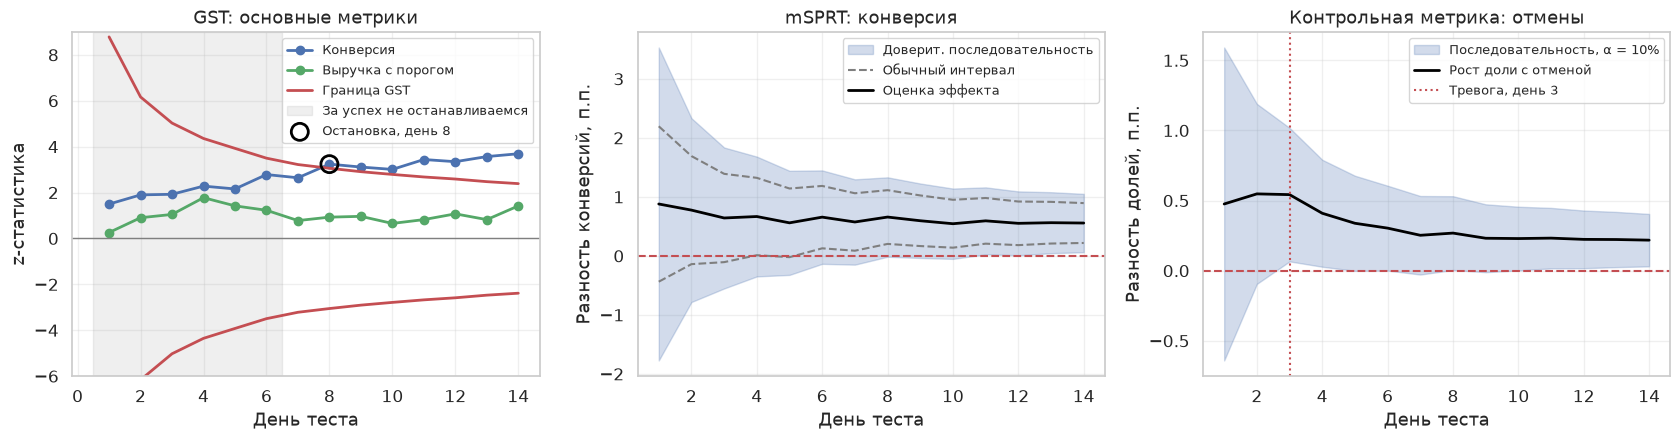

,share,diff,z,bound
day,,,,
7,0.499,0.006,2.642,3.218
8,0.566,0.007,3.237,3.056
9,0.633,0.006,3.109,2.907


In [26]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
d = gst_conv.index
axes[0].plot(d, gst_conv["z"], "-o", color=BLUE, linewidth=2, label="Конверсия")
axes[0].plot(d, gst_rev["z"], "-o", color=GREEN, linewidth=2, label="Выручка с порогом")
axes[0].plot(d, gst_conv["bound"], color=RED, linewidth=2, label="Граница GST")
axes[0].plot(d, -gst_conv["bound"], color=RED, linewidth=2)
axes[0].axvspan(0.5, MIN_DAY_SUCCESS - 0.5, color=GRAY, alpha=0.12, label="За успех не останавливаемся")
axes[0].axhline(0, color=GRAY, linewidth=1)
axes[0].scatter([stop_day], [gst_conv.loc[stop_day, "z"]], s=150, facecolor="none", edgecolor="black", linewidth=2, zorder=4,
                label=f"Остановка, день {stop_day}")
axes[0].set(xlabel="День теста", ylabel="z-статистика", ylim=(-6, 9), title="GST: основные метрики")
axes[0].legend(fontsize=9, loc="upper right")

fixed = norm.ppf(1 - ALPHA_PRIMARY / 2) * np.sqrt(msprt_conv["V"])
axes[1].fill_between(d, 100 * (msprt_conv["diff"] - msprt_conv["radius"]), 100 * (msprt_conv["diff"] + msprt_conv["radius"]),
                     color=BLUE, alpha=0.25, label="Доверит. последовательность")
axes[1].plot(d, 100 * (msprt_conv["diff"] - fixed), color=GRAY, linestyle="--", linewidth=1.5, label="Обычный интервал")
axes[1].plot(d, 100 * (msprt_conv["diff"] + fixed), color=GRAY, linestyle="--", linewidth=1.5)
axes[1].plot(d, 100 * msprt_conv["diff"], color="black", linewidth=2, label="Оценка эффекта")
axes[1].axhline(0, color=RED, linestyle="--", linewidth=1.5)
axes[1].set(xlabel="День теста", ylabel="Разность конверсий, п.п.", title="mSPRT: конверсия")
axes[1].legend(fontsize=9)

axes[2].fill_between(d, 100 * (msprt_cancel["diff"] - msprt_cancel["radius"]), 100 * (msprt_cancel["diff"] + msprt_cancel["radius"]),
                     color=BLUE, alpha=0.25, label="Последовательность, α = 10%")
axes[2].plot(d, 100 * msprt_cancel["diff"], color="black", linewidth=2, label="Рост доли с отменой")
axes[2].axhline(0, color=RED, linestyle="--", linewidth=1.5)
axes[2].axvline(harm_day, color=RED, linestyle=":", linewidth=1.5, label=f"Тревога, день {harm_day}")
axes[2].set(xlabel="День теста", ylabel="Разность долей, п.п.", title="Контрольная метрика: отмены")
axes[2].legend(fontsize=9)
plt.tight_layout()
plt.show()
gst_conv.loc[stop_day - 1: stop_day + 1, ["share", "diff", "z", "bound"]]

На 8-й день конверсия пересекла границу GST. Оценка — около **+0.66 п.п.**, на треть выше MDE. Продакт пишет: «Конверсия +14%, раскатываем!» Метод корректный, $\alpha$ под контролем. Но оценка в момент ранней остановки — не то же, что эффект. Измерим, насколько она завышена, в чистых условиях: эффект постоянный, без новизны.

**5а. Реализуйте `stopped_estimates(effect, boundaries, looks, n_paths, seed)`.** `effect` задан в долях MDE (снос `effect * THETA_MDE`). Сгенерируйте пути накопленной оценки $\hat\Delta(t) = B(t)/t$ в единицах $\sqrt{V_{\text{план}}}$, остановите каждый на первом $|Z| \ge b_i$ и верните:

1. номер взгляда остановки (последний, если остановки не было), с 1;
2. флаг срабатывания;
3. отношение оценки в момент остановки к истинному эффекту.

In [27]:
def stopped_estimates(effect: float, boundaries=BOUNDS_OBF, looks=LOOKS, n_paths: int = 400_000, seed: int = 3) -> tuple:
    # ВАШ КОД
    raise NotImplementedError

In [28]:
# @title Решение (нажмите, чтобы раскрыть)
def stopped_estimates(effect: float, boundaries=BOUNDS_OBF, looks=LOOKS, n_paths: int = 400_000, seed: int = 3) -> tuple:
    drift = effect * THETA_MDE
    z = drift_paths(looks, drift, n_paths, seed)
    estimates = z / np.sqrt(looks)                 # B(t) / t
    hits = np.abs(z) >= boundaries
    fired = hits.any(axis=1)
    last = np.where(fired, hits.argmax(axis=1), len(looks) - 1)
    return last + 1, fired, estimates[np.arange(n_paths), last] / drift

In [29]:
# Проверка: без ранней остановки оценка несмещена
_, _, single_ratio = stopped_estimates(1.0, boundaries=np.array([99.0]), looks=np.array([1.0]))
assert abs(single_ratio.mean() - 1) < 0.01, "Один взгляд в конце: оценка должна быть несмещённой"

rows, cache = [], {}
for effect in (0.5, 1.0, 1.5):
    stop_look, fired, ratio = cache[effect] = stopped_estimates(effect)
    early = fired & (stop_look <= 8)
    rows.append({"Эффект, MDE": effect, "Мощность": fired.mean(), "Завышение, все тесты": ratio.mean(),
                 "Завышение, значимые": ratio[fired].mean(), "Доля остановок до дня 8": early.mean(),
                 "Завышение, остановки до дня 8": ratio[early].mean()})
overestimation = pd.DataFrame(rows).set_index("Эффект, MDE")
assert overestimation.loc[1.0, "Завышение, остановки до дня 8"] > 1.3, "Ранние остановки должны заметно завышать эффект"
print("Задание 5а принято")
overestimation

Задание 5а принято


,Мощность,"Завышение, все тесты","Завышение, значимые",Доля остановок до дня 8,"Завышение, остановки до дня 8"
"Эффект, MDE",,,,,
0.500,0.263,1.076,2.028,0.041,2.950
1.000,0.839,1.103,1.210,0.309,1.567
1.500,0.996,1.077,1.080,0.773,1.178


* Если эффект равен MDE и тест остановился до 8-го дня включительно, оценка в среднем завышена примерно в **1.6 раза**.
* Если эффект вдвое меньше MDE, ранние остановки завышают его почти втрое.
* По всем тестам вместе смещение скромное. Но на столе у нас именно рано остановленный тест.

Механизм простой: рано пройти высокую границу O'Brien-Fleming можно только с большой оценкой, и чаще всего её даёт шум, подыгравший эффекту.

Обычный интервал вокруг такой оценки тоже смещён. Готовая `coverage_at_stop` считает, как часто интервал в момент остановки накрывает истинный эффект (заявлено 97.5%): обычный, **повторный доверительный интервал GST** $\hat\Delta \pm b_i\sqrt{V}$ и последовательность mSPRT.

In [30]:
def coverage_at_stop(effect: float = 1.0, max_day: int = PLAN_DAYS) -> pd.Series:
    stop_look, fired, ratio = cache[effect]
    chosen = fired & (stop_look <= max_day)
    t = LOOKS[stop_look - 1]
    error = np.abs(ratio - 1) * effect * THETA_MDE
    half_naive = norm.ppf(1 - ALPHA_PRIMARY / 2) / np.sqrt(t)
    half_gst = BOUNDS_OBF[stop_look - 1] / np.sqrt(t)
    half_msprt = msprt_radius(1 / t, TAU / np.sqrt(V_PLAN))
    return pd.Series({"Обычный интервал": (error <= half_naive)[chosen].mean(),
                      "Повторный интервал GST": (error <= half_gst)[chosen].mean(),
                      "Последовательность mSPRT": (error <= half_msprt)[chosen].mean()})


coverage = pd.DataFrame({**{f"{e} MDE, все остановки": coverage_at_stop(e) for e in (0.5, 1.0)},
                         **{f"{e} MDE, до дня 8": coverage_at_stop(e, 8) for e in (0.5, 1.0)}})
coverage.T

,Обычный интервал,Повторный интервал GST,Последовательность mSPRT
"0.5 MDE, все остановки",0.928,0.999,0.998
"1.0 MDE, все остановки",0.980,1.000,1.000
"0.5 MDE, до дня 8",0.561,0.997,0.987
"1.0 MDE, до дня 8",0.947,1.000,0.999


Среди ранних остановок обычный интервал теряет покрытие (сильнее всего при малом эффекте), а повторный интервал и последовательность mSPRT держат уровень при любом дне остановки. В отчёте показываем их.

**5б. Честный отчёт.** Соберите словарь `honest` для дня остановки `stop_day` по конверсии, в п.п.: `estimate` — точечная оценка; `gst_low`, `gst_high` — повторный интервал GST ($\hat\Delta \pm b_i\sqrt{V}$, из `gst_conv`); `msprt_low`, `msprt_high` — последовательность mSPRT (из `msprt_conv`).

In [31]:
# ВАШ КОД
raise NotImplementedError

NotImplementedError: 

In [32]:
# @title Решение (нажмите, чтобы раскрыть)
g, m = gst_conv.loc[stop_day], msprt_conv.loc[stop_day]
honest = {"estimate": 100 * g["diff"],
          "gst_low": 100 * (g["diff"] - g["radius"]), "gst_high": 100 * (g["diff"] + g["radius"]),
          "msprt_low": 100 * (m["diff"] - m["radius"]), "msprt_high": 100 * (m["diff"] + m["radius"])}
print(f"День {stop_day}: оценка {honest['estimate']:+.2f} п.п., повторный интервал GST [{honest['gst_low']:+.2f}; {honest['gst_high']:+.2f}], "
      f"mSPRT [{honest['msprt_low']:+.2f}; {honest['msprt_high']:+.2f}]")

День 8: оценка +0.66 п.п., повторный интервал GST [+0.04; +1.28], mSPRT [-0.02; +1.33]


In [33]:
# Проверка
assert abs(honest["estimate"] - 100 * cum_conv.loc[stop_day, "diff"]) < 1e-9
assert honest["gst_low"] > 0, "Граница пройдена — повторный интервал не содержит ноль"
assert np.isclose(honest["gst_high"] - honest["gst_low"], 2 * 100 * gst_conv.loc[stop_day, "bound"] * np.sqrt(cum_conv.loc[stop_day, "V"]))
assert honest["msprt_low"] < honest["gst_low"] < honest["estimate"] < honest["gst_high"] < honest["msprt_high"]
print("Задание 5б принято")

Задание 5б принято


Отчёт на 8-й день звучит так: «эффект на конверсию есть, повторный 97.5%-интервал — от +0.04 до +1.28 п.п.», а не «+0.66 п.п., +14%». Интервал сразу показывает, как мало мы знаем о размере эффекта: от «почти ноль» до «вдвое больше MDE».

## Задание 6. Решение и политика остановки (5 минут)

Блок проработал 28 дней — откроем весь лог. Интервалы ниже — доверительные последовательности mSPRT: они корректны на любой день. Для отмен добавлены обычный односторонний p-value и доля отмен **среди броней**.

In [34]:
def status(result: pd.DataFrame, day: int, scale: float) -> str:
    row = result.loc[day]
    return f"{row['diff'] * scale:+.2f} [{(row['diff'] - row['radius']) * scale:+.2f}; {(row['diff'] + row['radius']) * scale:+.2f}]"


def cancel_among_bookings(df: pd.DataFrame) -> str:
    booked = df[df["booked"] == 1].groupby("group")["cancelled"].agg(["mean", "size"])
    diff = booked.loc["B", "mean"] - booked.loc["A", "mean"]
    se = np.sqrt((booked["mean"] * (1 - booked["mean"]) / booked["size"]).sum())
    return f"{100 * booked.loc['A', 'mean']:.1f}% → {100 * booked.loc['B', 'mean']:.1f}% (p = {norm.sf(diff / se):.3f})"


full_conv = replay_msprt(daily_cumulative(logs, "booked"), TAU)
full_rev = replay_msprt(daily_cumulative(logs, "revenue_capped"), TAU_REV)
full_cancel = replay_msprt(daily_cumulative(logs, "cancelled"), TAU_CANCEL, alpha=2 * ALPHA)
report = pd.DataFrame({f"День {d}": {
    "Конверсия, п.п.": status(full_conv, d, 100),
    "Выручка с порогом, ₽": status(full_rev, d, 1),
    "Доля с отменой, п.п. (α = 10%)": status(full_cancel, d, 100),
    "Доля с отменой: односторонний p": f"{norm.sf(full_cancel.loc[d, 'diff'] / np.sqrt(full_cancel.loc[d, 'V'])):.3f}",
    "Отмены среди броней, A → B": cancel_among_bookings(logs[logs["day"] <= d]),
} for d in (harm_day, stop_day, 14, 28)})
report

,День 3,День 8,День 14,День 28
"Конверсия, п.п.",+0.64 [-0.55; +1.84],+0.66 [-0.02; +1.33],+0.56 [+0.06; +1.05],+0.35 [-0.00; +0.70]
"Выручка с порогом, ₽",+135.73 [-327.91; +599.36],+73.77 [-189.82; +337.36],+83.13 [-109.41; +275.68],-8.17 [-143.30; +126.95]
"Доля с отменой, п.п. (α = 10%)",+0.54 [+0.07; +1.02],+0.27 [+0.00; +0.53],+0.22 [+0.03; +0.40],+0.14 [+0.01; +0.28]
Доля с отменой: односторонний p,0.000,0.002,0.001,0.002
"Отмены среди броней, A → B",15.1% → 23.6% (p = 0.001),18.8% → 21.4% (p = 0.052),18.1% → 20.3% (p = 0.035),18.7% → 20.2% (p = 0.043)


**6а.** Напишите продакту 3–5 предложений: что с метриками, раскатываем ли блок, что дальше.

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

* **Отмены.** Тревога по контрольной метрике — уже на 3-й день: доля пользователей с отменой выросла, последовательность исключает ноль. По политике это эскалация в тот же день, раньше любого решения об успехе: раскатка с этого момента запрещена, а тест продолжается только для диагностики. Часть роста механическая (броней больше — и отмен больше), но и доля отмен **среди броней** выше в B: 18.7% против 20.2% к дню 28.
* **Конверсия.** Рост есть, но оценка дня остановки (+0.66 п.п.) завышена: к дню 28 накопленная оценка опускается до +0.35 п.п., а поздние когорты слабее ранних.
* **Выручка.** Значимого роста нет ни на один день: скидки съедают прирост броней.

**Решение: блок в текущем виде не раскатываем.** По правилу, принятому до старта, рост конверсии не открывает раскатку, потому что контрольная метрика значимо ухудшилась. Предлагаем разобраться с отменами и глубиной скидок, а новый тест запустить с минимальной длительностью две недели и guardrail «доля отмен среди броней».

</details>

**6б. Политика остановки.** Откройте шаблон `stopping_policy.md` из папки встречи и заполните его для «Горящих предложений»: расписание взглядов, границы эффективности и futility, минимальная длительность, матрица эскалации, правила отчёта. Числа берите из заданий 2–5.

<details>
<summary><b>Пример заполнения</b> (нажмите, чтобы раскрыть)</summary>

**1. Тест и метрики.** «Горящие предложения» на главной; единица — пользователь, момент входа — первый заход на главную. Основные: конверсия в бронирование и выручка на пользователя (порог 196 тыс. ₽, зафиксирован по истории), $\alpha = 2.5\%$ на каждую (двусторонний). Guardrail: доля пользователей с отменой, тревога при одностороннем 5%. MDE +0.5 п.п. при базе 4.8%. Фиксированный тест — 36.5 тыс. на группу, 12.2 дня. Раскатываем, если значимо выросла хотя бы одна основная метрика и guardrail значимо не ухудшился.

**2. Расписание.** Продакт смотрит дашборд каждый день, на дашборде только повторные интервалы. Взгляды по эффективности — ежедневно, дни 1–14; доля информации — по факту. Futility — дни 7 и 10. Guardrail — mSPRT каждый день с первого дня.

**3. Эффективность.** GST, O'Brien-Fleming: $N_{\max}$ известен, взглядов 14. Запас $R \approx 1.05$, округлено до двух недель: $N_{\max} = 42\,000$ на группу. Границы $\lvert Z\rvert$: 8.4 в день 1, 3.2 в день 7, 2.4 в день 14. Мощность при MDE ≈ 84%.

**4. Futility.** $\mathrm{CP}(\theta_{\text{MDE}}) < 0.2$ на днях 7 и 10, то есть $z < 0.21$ на день 7 и $z < 1.18$ на день 10 (по плановым долям; по факту пересчитываем). Non-binding. При $H_0$ средняя выборка — 62% $N_{\max}$ вместо 100%; потеря мощности при MDE ≈ 0.6 п.п.

**5. Длительность.** За успех — не раньше дня 7; если граница пройдена раньше, ждём день 7 и проверяем снова. За вред — в любой день. Перед решением — эффект по недельным когортам. Нет пересечения к дню 14 — тест закрыт: «эффект ≥ MDE маловероятен, меньший не исключён». За день 14 не продлеваем.

**6. Матрица эскалации.**

| Ситуация | Действие | Кто решает | Срок |
| --- | --- | --- | --- |
| Успех: граница пройдена, день ≥ 7, guardrail чистые | стоп; отчёт с повторным интервалом и когортами; раскатка с holdout 5% на месяц | продакт по отчёту аналитика | 1 день |
| Вред по guardrail: последовательность исключает ноль | эскалация владельцу метрики; раскатка запрещена; тест на паузу или продолжаем только для диагностики | владелец guardrail + продакт | в тот же день |
| Вред по основной: нижняя граница | стоп, откат, разбор | продакт | в тот же день |
| «Ничего не происходит»: futility или день 14 без пересечения | стоп; отчёт с интервалом; идея — на доработку или в архив | продакт | 1 день |
| SRM или сбой логирования | пауза; чек-лист встречи 3; дни со сбоем — в журнал | аналитик | в тот же день |
| «Ещё неделю» | нет; новый тест с новым планом или результат «разведочный» | аналитик | — |

**7. Отчёт.** «День 8 ($t = 0.57$), $z = 3.24$ при границе 3.06. Эффект на конверсию есть: повторный 97.5%-интервал от +0.04 до +1.28 п.п.; точечная оценка +0.66 п.п. завышена ранней остановкой. Guardrail: тревога по отменам с дня 3 — раскатка запрещена правилом решения. Отклонений от плана нет; результат подтверждающий».

**8. Журнал.** Блок проработал 28 дней из-за заморозки релизов; дни 15–28 используем только для разведочного анализа когорт.

</details>

### Как было на самом деле

> **Только для разбора.** Ниже — истинные параметры генератора данных. В реальном тесте их не узнать; здесь они нужны, чтобы проверить выводы.

Истинный эффект на конверсию для когорты дня $d$: $0.2 + 0.8\,e^{-(d-1)/4}$ п.п. — новизна, которая затухает за 1–2 недели; долгосрочный эффект **+0.2 п.п.**, в 2.5 раза меньше MDE. Брони в B на 5% дешевле из-за скидок. Доля отмен среди броней выросла с 18% до 19.5%.

In [35]:
def true_effect(day):
    """Истинный эффект на конверсию для когорты дня day (с 1) — из генератора данных."""
    return 0.002 + 0.008 * np.exp(-(np.asarray(day) - 1) / 4)


cohort = (logs["day"] - 1) // 7 + 1
weekly = logs.groupby([cohort, "group"])["booked"].mean().unstack()
pd.DataFrame({"Оценка по когорте, п.п.": 100 * (weekly["B"] - weekly["A"]).values,
              "Истина, п.п.": [100 * true_effect(np.arange(a, a + 7)).mean() for a in (1, 8, 15, 22)],
              "Накопленная оценка на конец недели, п.п.": [100 * full_conv.loc[d, "diff"] for d in (7, 14, 21, 28)]},
             index=["дни 1–7", "дни 8–14", "дни 15–21", "дни 22–28"]).round(2)

,"Оценка по когорте, п.п.","Истина, п.п.","Накопленная оценка на конец недели, п.п."
дни 1–7,0.570,0.630,0.570
дни 8–14,0.540,0.270,0.560
дни 15–21,0.100,0.210,0.410
дни 22–28,0.180,0.200,0.350


Оценка на день остановки (+0.66 п.п.) завышает долгосрочный эффект (+0.2 п.п.) в 3.3 раза. Здесь сложились две причины: отбор ранней остановки (задание 5) и новизна. Против первой работают повторный интервал и минимальная длительность. Против второй — только анализ по когортам и holdout после раскатки: никакая поправка $\alpha$ не превращает реакцию первых пользователей в реакцию будущих.

## Итог

* Ежедневный взгляд в обычный тест — около 22% ложных срабатываний вместо 5%.
* GST с O'Brien-Fleming разрешает смотреть каждый день за запас выборки ~5% (Pocock — ~25%). Наш план: 14 дней, $N_{\max} = 42\,000$ на группу.
* mSPRT не требует $N_{\max}$, $\tau$ берём из плана ($\approx$ MDE); платим мощностью. Ему место на guardrail и в тестах с неизвестной длительностью.
* Futility по условной мощности при эффекте из плана экономит ~40% выборки при $H_0$ и почти не стоит мощности; делаем non-binding.
* Ранняя остановка завышает оценку; в отчёт — повторный интервал, а не точечная оценка.
* Статистически честная остановка не гарантирует верного продуктового решения: смотрим guardrail, когорты и минимальную длительность.

Артефакт встречи — заполненная `stopping_policy.md`. Во встрече 6 на этих же данных разберём сегменты и мемо.

## Дополнительные задания

Кратко, без готовых решений; формулы — в `theory.ipynb`.

1. **Выручка и тяжёлый хвост.** Посчитайте скошенность выручки на пользователя и правило Кохави $n \ge 355 s^2$ до и после порога 196 тыс. ₽. Прогоните 2 000 A/A-тестов с 14 взглядами при 300 и 6 000 пользователях в день и сплитах 50/50 и 80/20: где GST на выручке начинает ложно срабатывать? Какой MDE по выручке даёт наш $N_{\max}$ с порогом и без?
2. **Прогон своими руками.** Напишите `daily_cumulative`, `replay_gst` и `replay_msprt` сами и сверьте с готовыми.
3. **Эффект по когортам.** Оцените эффект отдельно по недельным и дневным когортам с 95% ДИ. Значимо ли отличается первая неделя от дней 8–28?
4. **Правило минимальной длительности.** На 20 000 симуляций с затухающим эффектом сравните: первое срабатывание GST; не раньше дня 7; взгляды только на днях 7 и 14; один взгляд на день 14; один на день 28; только когорты дней 8–14. Какое правило ближе к долгосрочному эффекту и чем платит?
5. **Выход за $N_{\max}$.** Продакт просит «ещё неделю» после дня 14. Посчитайте ложные срабатывания, если проверять каждый день по последней границе и если один раз в конце. А у mSPRT?
6. **Binding на практике.** Повторите сравнение binding / non-binding для futility по текущему тренду. Почему разница границ теперь больше?
7. **CUPED внутри GST.** Снижение дисперсии на 30% уменьшает $V$ на каждом взгляде. Сколько дней это сэкономит и почему долю данных тогда считают по информации, а не по числу пользователей?